<a href="https://colab.research.google.com/github/KarlaMichelleSorianoSanhez/Simulacion-II/blob/main/SIR_con_pymc.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<h1><font color="#D97706">Ajuste de parámetros del modelo SIR mediante inferencia bayesiana</font></h1>

**Materia:** Simulación II

**Instrucciones:** Resolver el ajuste de parámetros del modelo SIR utilizando un enfoque bayesiano y la biblioteca PyMC de Python. Explicar el enfoque y la interpretación de las gráficas obtenidas.

<h2><font color="#D97706">Objetivo</font></h2>

Estimar los parámetros de transmisión y recuperación del modelo SIR a partir de los datos de un brote de influenza, utilizando inferencia bayesiana. Además, analizar las distribuciones obtenidas y la convergencia de las cadenas de Markov para evaluar los resultados.

<h2><font color="#D97706">1. Preparación del entorno de trabajo</font></h2>

Para realizar el ajuste bayesiano utilizaremos **PyMC**, que permite construir modelos probabilísticos y estimar sus parámetros. También emplearemos **ArviZ** para analizar las distribuciones obtenidas y revisar la convergencia de las cadenas.

In [11]:
# Instalamos las bibliotecas necesarias para el análisis bayesiano
%pip install -q pymc arviz

<h2><font color="#D97706">2. Planteamiento del problema</font></h2>

El modelo SIR permite estudiar la propagación de una enfermedad al dividir a la población en tres grupos: susceptibles ($S$), infectados ($I$) y recuperados ($R$).

En el artículo *The inverse problem of a dynamical system solved with genetic algorithms* se analiza un brote de influenza en un internado con 763 estudiantes, utilizando los registros de infectados durante 15 días.

El problema consiste en determinar los parámetros $a$ y $b$ del modelo SIR a partir de estos datos. Mientras que el artículo utiliza algoritmos genéticos, en esta actividad emplearemos inferencia bayesiana para estimar los parámetros y conocer la incertidumbre asociada a sus valores.

<h2><font color="#D97706">3. Modelo matemático SIR</font></h2>

De acuerdo con el artículo, el modelo SIR está formado por el siguiente sistema de ecuaciones diferenciales:

$$
\begin{aligned}
\frac{dS}{dt} &= -aSI,\\[6pt]
\frac{dI}{dt} &= aSI-bI,\\[6pt]
\frac{dR}{dt} &= bI.
\end{aligned}
$$

Donde:

- $S(t)$: número de personas susceptibles.
- $I(t)$: número de personas infectadas.
- $R(t)$: número de personas recuperadas.
- $a$: parámetro de transmisión.
- $b$: tasa de recuperación.

La primera ecuación describe la disminución de susceptibles debido a los contagios. La segunda representa el cambio en los infectados, considerando nuevos contagios y recuperaciones. La tercera describe el aumento de recuperados.

Como se considera una población cerrada, el número total de estudiantes permanece constante:

$$
S(t)+I(t)+R(t)=N=763.
$$

<h2><font color="#D97706">4. Datos observados</font></h2>

Utilizaremos los registros de infectados presentados en el artículo, correspondientes a 15 días de observación.

Al inicio del registro se tiene un estudiante infectado. Por lo tanto, las condiciones iniciales son:

$$
S(0)=762,\qquad I(0)=1,\qquad R(0)=0.
$$

Estos datos permitirán comparar el comportamiento observado de la enfermedad con las predicciones del modelo SIR.

In [12]:
# Biblioteca para trabajar con arreglos numéricos
import numpy as np

# Número total de estudiantes
N = 763

# Días de observación, comenzando en t = 0
t = np.arange(15)

# Número de infectados registrado en el artículo
I_obs = np.array([
    1, 3, 6, 25, 73, 222, 294, 258,
    237, 191, 125, 69, 27, 11, 4
])

# Condiciones iniciales del modelo SIR
S0 = 762
I0 = 1
R0 = 0

# Mostramos los datos registrados
print("Días:", t)
print("Infectados:", I_obs)

Días: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14]
Infectados: [  1   3   6  25  73 222 294 258 237 191 125  69  27  11   4]


<h3><font color="#D97706">4.1. Comportamiento de los datos observados</font></h3>

Antes de realizar el ajuste, representaremos los datos para observar cómo cambió el número de infectados durante el brote.

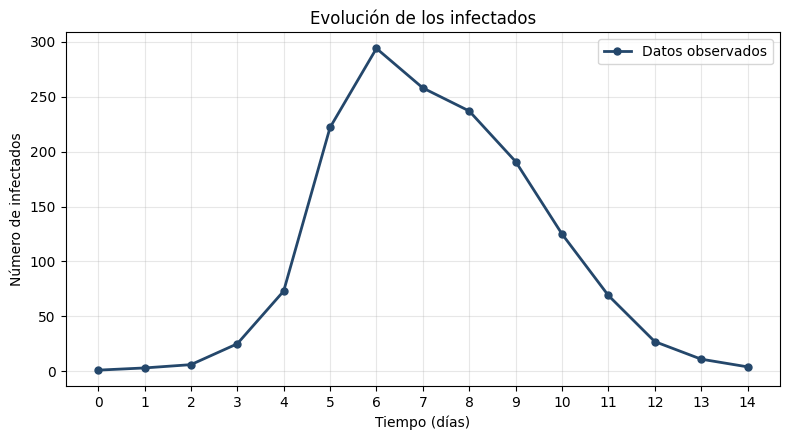

In [13]:
# Biblioteca para realizar gráficas
import matplotlib.pyplot as plt

# Graficamos el número de infectados a lo largo del tiempo
plt.figure(figsize=(8, 4.5))

plt.plot(
    t, I_obs,
    marker="o",
    linestyle="-",
    color="#24476B",
    linewidth=2,
    markersize=5,
    label="Datos observados"
)

# Agregamos el título y los nombres de los ejes
plt.title("Evolución de los infectados")
plt.xlabel("Tiempo (días)")
plt.ylabel("Número de infectados")

# Ajustamos la presentación de la gráfica
plt.xticks(t)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()

plt.show()

**Observación:** El número de infectados aumenta durante los primeros días hasta alcanzar un máximo de 294 estudiantes en el día 6. Después comienza a disminuir, lo que muestra el crecimiento y posterior descenso del brote.

Este comportamiento será el que intentaremos reproducir mediante el ajuste de los parámetros del modelo SIR.

<h2><font color="#D97706">5. Enfoque bayesiano</font></h2>

La inferencia bayesiana permite estimar parámetros combinando la información que tenemos antes de observar los datos con la información que estos proporcionan.

De acuerdo con Sivia y Skilling, este procedimiento se basa en el teorema de Bayes:

$$
p(a,b\mid D)=\frac{p(D\mid a,b)\,p(a,b)}{p(D)}.
$$

En nuestro problema:

- **$p(a,b)$ — Distribución a priori:** representa la información inicial sobre los parámetros de transmisión y recuperación.
- **$p(D\mid a,b)$ — Verosimilitud:** indica qué tan compatibles son los datos observados con los valores de $a$ y $b$.
- **$p(a,b\mid D)$ — Distribución posterior:** representa la información actualizada sobre los parámetros después de considerar los datos.
- **$p(D)$ — Evidencia:** permite normalizar la distribución posterior.

Como la evidencia no depende de los parámetros que queremos estimar, podemos expresar la relación como:

$$
p(a,b\mid D)\propto p(D\mid a,b)\,p(a,b).
$$

Así, en lugar de obtener únicamente un valor para cada parámetro, podremos conocer sus distribuciones posteriores y la incertidumbre de las estimaciones.

<h3><font color="#D97706">5.1. Distribuciones a priori</font></h3>

Los parámetros $a$ y $b$ deben ser positivos, ya que representan la transmisión y la recuperación de la enfermedad.

Para comenzar, utilizaremos distribuciones uniformes independientes:

$$
a\sim U(0,0.01),
$$

$$
b\sim U(0,1).
$$

La distribución uniforme considera igualmente posibles los valores dentro del intervalo establecido, antes de incorporar los datos.

El intervalo de $b$ sigue el rango de búsqueda utilizado en el artículo. Para $a$ utilizamos un intervalo menor porque las ecuaciones trabajan con el número de estudiantes, y el término de contagio depende del producto $SI$.

Estas distribuciones son una elección para nuestro análisis bayesiano; no son resultados obtenidos del artículo.

<h3><font color="#D97706">5.2. Verosimilitud</font></h3>

La verosimilitud relaciona los datos observados con los valores que predice el modelo SIR.

Para cada combinación de $a$ y $b$, resolveremos las ecuaciones diferenciales y obtendremos una curva de infectados $I(t)$.

Como nuestros datos representan cantidades de estudiantes infectados, utilizaremos una distribución de Poisson:

$$
I_{\mathrm{obs},i}\mid a,b
\sim
\operatorname{Poisson}\bigl(I(t_i;a,b)\bigr).
$$

Esto significa que el número de infectados observado en cada día se modelará alrededor del valor que predice el sistema SIR.

La distribución de Poisson es una elección para representar los datos de conteo. En este caso, supone que la varianza de cada observación es igual a su media y que las observaciones son independientes una vez conocidos los parámetros.

Utilizaremos los días posteriores al inicial para construir la verosimilitud, porque el valor $I(0)=1$ ya está fijado como condición inicial.

<h3><font color="#D97706">5.3. Distribución posterior</font></h3>

Al combinar las distribuciones a priori con la verosimilitud, obtenemos la distribución posterior:

$$
p(a,b\mid D)\propto p(D\mid a,b)\,p(a)\,p(b).
$$

Esta distribución nos permitirá identificar los valores de $a$ y $b$ más compatibles con los datos y conocer su incertidumbre.

Como el cálculo de la posterior no es sencillo de realizar directamente, utilizaremos PyMC y el método MCMC para obtener muestras de ella.

<h3><font color="#D97706">5.4. Muestreo mediante MCMC</font></h3>

Los métodos de Monte Carlo mediante cadenas de Markov (MCMC) permiten obtener muestras de una distribución de probabilidad que resulta difícil calcular directamente.

En nuestro caso, utilizaremos el algoritmo NUTS, disponible en PyMC, para obtener muestras de la distribución posterior de los parámetros.

Inicialmente consideraremos:

- 4 cadenas de Markov.
- 1000 iteraciones de ajuste inicial por cadena.
- 2000 muestras posteriores por cadena.

Las iteraciones iniciales se utilizan para adaptar el algoritmo y no se incluyen en las muestras posteriores.

Posteriormente revisaremos las gráficas de las cadenas y los diagnósticos de convergencia. Si es necesario, ajustaremos la configuración del muestreo.

<h2><font color="#D97706">6. Solución numérica del modelo SIR</font></h2>

Para conocer el comportamiento de los grupos susceptibles, infectados y recuperados, necesitamos resolver el sistema de ecuaciones diferenciales.

Utilizaremos la función `solve_ivp` de SciPy, que permite obtener una solución numérica a partir de las ecuaciones y las condiciones iniciales.

Primero definiremos el sistema conservando la notación $a$ y $b$ del artículo.

In [14]:
# Biblioteca para resolver ecuaciones diferenciales
from scipy.integrate import solve_ivp

# Definimos el sistema SIR del artículo
def sir(t, y, a, b):

    S, I, R = y

    # Cambio de susceptibles, infectados y recuperados
    dS = -a * S * I
    dI = a * S * I - b * I
    dR = b * I

    return [dS, dI, dR]

<h3><font color="#D97706">6.1. Comprobación del modelo</font></h3>

Para comprobar la solución numérica, utilizaremos los parámetros obtenidos mediante algoritmos genéticos en el artículo:

$$
a=0.00205,\qquad b=0.43552.
$$

Con estos valores resolveremos el sistema SIR y compararemos el número de infectados que predice con los datos observados.

In [15]:
# Valores de referencia reportados en el artículo
a_ref = 0.00205
b_ref = 0.43552

# Condiciones iniciales
y0 = [S0, I0, R0]

# Resolvemos el sistema en los días registrados
solucion = solve_ivp(
    sir,
    t_span=(t[0], t[-1]),
    y0=y0,
    t_eval=t,
    args=(a_ref, b_ref),
    rtol=1e-8,
    atol=1e-10
)

# Comprobamos que la solución se obtuvo correctamente
if not solucion.success:
    raise RuntimeError(solucion.message)

# Separamos las soluciones de cada grupo
S_ref, I_ref, R_ref = solucion.y

# Verificamos que la población total se conserve
print("Población inicial:", N)
print("Población al último día:", round(S_ref[-1] + I_ref[-1] + R_ref[-1], 4))

Población inicial: 763
Población al último día: 763.0


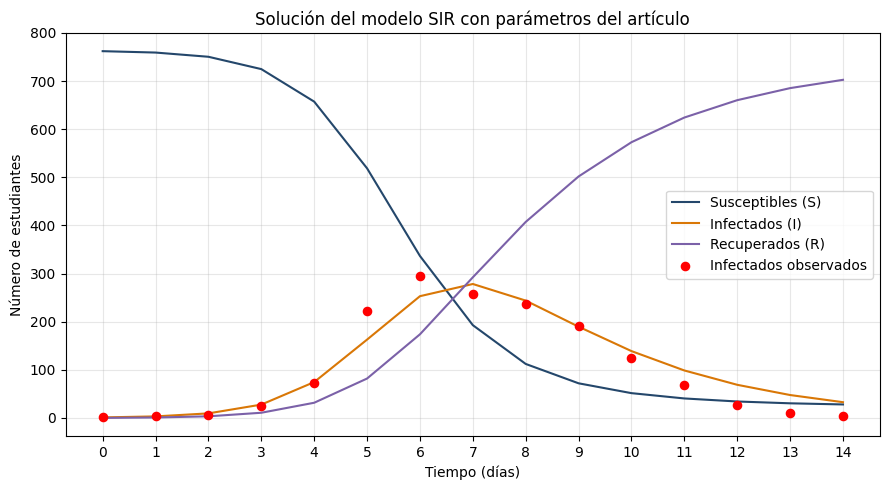

In [16]:
# Biblioteca para realizar gráficas
import matplotlib.pyplot as plt

# Graficamos las tres soluciones del modelo SIR
plt.figure(figsize=(9, 5))

plt.plot(t, S_ref, color="#24476B", label="Susceptibles (S)")
plt.plot(t, I_ref, color="#D97706", label="Infectados (I)")
plt.plot(t, R_ref, color="#7B61A8", label="Recuperados (R)")

# Agregamos los datos observados para compararlos
plt.scatter(
    t, I_obs,
    color="red",
    s=35,
    label="Infectados observados",
    zorder=3
)

plt.title("Solución del modelo SIR con parámetros del artículo")
plt.xlabel("Tiempo (días)")
plt.ylabel("Número de estudiantes")

plt.xticks(t)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()

plt.show()

**Observación:** La gráfica muestra que, conforme avanza el brote, disminuye el número de susceptibles y aumenta el de recuperados. Los infectados crecen hasta alcanzar un máximo y después comienzan a disminuir. Aunque la curva del modelo sigue una tendencia similar a los datos observados, existen algunas diferencias entre ambos.

Esto nos permite comprobar el comportamiento del modelo SIR antes de realizar el ajuste bayesiano.

<h2><font color="#D97706">7. Preparación del ajuste bayesiano</font></h2>

Una vez comprobado el funcionamiento del modelo SIR, el siguiente paso es estimar los parámetros $a$ y $b$ mediante PyMC.

A diferencia de la comprobación anterior, ahora no fijaremos los parámetros en los valores del artículo. Utilizaremos las distribuciones a priori y los datos observados para obtener sus distribuciones posteriores.

Para ello, necesitaremos que PyMC pueda resolver el sistema SIR durante el muestreo.

<h2><font color="#D97706">8. Implementación del modelo bayesiano en PyMC</font></h2>

Para estimar los parámetros $a$ y $b$, necesitamos resolver el modelo SIR para distintos valores de ambos parámetros.

Utilizaremos las ecuaciones del artículo, pero ahora con una solución numérica compatible con PyMC. Esto permitirá que el algoritmo NUTS explore los valores de los parámetros durante el muestreo.

Como trabajamos con los números de estudiantes y no con proporciones, conservaremos la misma escala y notación del artículo.

In [17]:
# Biblioteca para realizar operaciones compatibles con PyMC
import pytensor.tensor as pt

# Definimos las ecuaciones del modelo SIR
def ecuaciones_sir(y, a, b):
    S, I, R = y[0], y[1], y[2]

    dS = -a * S * I
    dI = a * S * I - b * I
    dR = b * I

    return pt.stack([dS, dI, dR])


# Un paso del método de Runge-Kutta de cuarto orden
def paso_rk4(y, a, b, h):
    k1 = ecuaciones_sir(y, a, b)
    k2 = ecuaciones_sir(y + h*k1/2, a, b)
    k3 = ecuaciones_sir(y + h*k2/2, a, b)
    k4 = ecuaciones_sir(y + h*k3, a, b)

    return y + h*(k1 + 2*k2 + 2*k3 + k4)/6


# Resolvemos el modelo en los 15 días de observación
def resolver_sir(a, b):

    y = pt.as_tensor_variable(
        np.array([S0, I0, R0], dtype="float64")
    )

    soluciones = [y]
    h = 0.1  # Diez pasos por día

    for dia in range(14):
        for paso in range(10):
            y = paso_rk4(y, a, b, h)

        soluciones.append(y)

    return pt.stack(soluciones)

<h3><font color="#D97706">8.1. Construcción del modelo probabilístico</font></h3>

Ahora incorporaremos las distribuciones a priori que definimos anteriormente y la verosimilitud de Poisson.

Para cada combinación de parámetros, el modelo SIR calculará el número esperado de infectados. PyMC comparará esos valores con los datos observados para construir la distribución posterior.

In [18]:
# Biblioteca para construir el modelo bayesiano
import pymc as pm

with pm.Model() as modelo_sir:

    # Distribuciones a priori de los parámetros
    a = pm.Uniform("a", lower=0, upper=0.01)
    b = pm.Uniform("b", lower=0, upper=1)

    # Solución del sistema SIR
    solucion_sir = resolver_sir(a, b)

    # Número esperado de infectados
    I_modelo = solucion_sir[1:, 1]

    # Evitamos valores no positivos en la distribución de Poisson
    I_modelo = pt.maximum(I_modelo, 1e-8)

    # Comparamos el modelo con los datos observados
    infectados = pm.Poisson(
        "infectados",
        mu=I_modelo,
        observed=I_obs[1:]
    )

<h3><font color="#D97706">8.2. Muestreo mediante NUTS</font></h3>

Utilizaremos cuatro cadenas de Markov para obtener muestras de la distribución posterior de los parámetros.

Inicialmente realizaremos 1000 iteraciones de ajuste y conservaremos 2000 muestras por cadena. Después revisaremos si las cadenas presentan una convergencia adecuada.

In [ ]:
# Biblioteca para realizar el muestreo bayesiano
import pymc as pm

with modelo_sir:

    idata = pm.sample(
        draws=2000,
        tune=1000,
        chains=4,
        cores=2,
        target_accept=0.9,
        random_seed=42,
        return_inferencedata=True
    )

/usr/local/lib/python3.13/dist-packages/pytensor/tensor/rewriting/elemwise.py:881: UserWarning: Loop fusion failed because the resulting node would exceed the kernel argument limit.
  warn(


<h2><font color="#D97706">9. Análisis de convergencia</font></h2>

Después del muestreo, revisaremos si las cadenas de Markov presentan una convergencia adecuada.

Para ello utilizaremos los estadísticos R-hat y ESS, además de comprobar si se produjeron divergencias durante el muestreo.

In [ ]:
# Biblioteca para analizar los resultados del muestreo
import arviz as az

# Resumen de los parámetros estimados
resumen = az.summary(idata, var_names=["a", "b"])

print(resumen)

# Número de divergencias durante el muestreo
divergencias = int(idata.sample_stats["diverging"].sum())

print("\nNúmero de divergencias:", divergencias)